# Этап 5. Проверка номинального режима

Код: `make_scene(kind='nominal')` в `rssrl/scenarios.py`, `unsafe_entries` в `rssrl/pilot.py`. Проверки: `tests/test_nominal.py`.

**Номинальный режим** — нарушителя нет. Все фоновые машины тормозят не сильнее 5 м/с² (a_max,brake), то есть продольное допущение RSS соблюдается. Если фильтр сделан правильно, с ним агент не должен попадать в столкновения.

Это проверка до всех экспериментов: если фильтр не справляется даже здесь, столкновения при β > 1 нельзя было бы приписать нарушителю.

**Агенты** (PPO еще не обучен):
- IDLE — держит полосу и целевую скорость, никого не объезжает;
- случайная политика — каждую секунду случайное действие из пяти, в том числе перестроения (seed политики = seed сцены + 1000).

Сцены 0–99, для каждой три варианта: фильтр с задержкой ρ = 0,5 с (основной), фильтр с задержкой 0 (дополнительный), без фильтра. У всех машин ускорение меняется не быстрее 10 м/с³; фильтр в экстренном режиме тормозит до 8 м/с²; d_min фильтра — лемма 2 с учетом рывка.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.pilot import run_grid, plot_episode, unsafe_entries

FIG = Path('..') / 'results' / 'figures'
PILOT = Path('..') / 'results' / 'pilot_05'  # таблицы пилота, в git не идут
PILOT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
SEEDS = range(100)
# основной режим — фильтр с задержкой ρ, дополнительный — мгновенный фильтр
VARIANTS = [(True, 0.5), (True, 0.0), (False, 0.5)]
NAMES = {(True, 0.5): 'фильтр, задержка ρ (основной)', (True, 0.0): 'фильтр, задержка 0 (доп.)',
         (False, 0.5): 'без фильтра'}

In [2]:
frames, LOGS = [], {}
for policy in ['idle', 'random']:
    o, logs = run_grid(SEEDS, [1.0], VARIANTS, kind='nominal', policy=policy)
    frames.append(o)
    LOGS[policy] = logs
outcomes = pd.concat(frames, ignore_index=True)
outcomes['вариант'] = [NAMES[(s, d)] for s, d in zip(outcomes['shield'], outcomes['reaction_delay'])]

def per_episode(policy, key):
    log = LOGS[policy][key]
    return {'доля времени фильтр тормозит': log['shield_active'].mean(),
            'мин. скорость, м/с': log['ego_v'].min(),
            'доля времени экстренно': (log['shield_mode'] == 'emergency').mean(),
            'опасных событий от фона': len(unsafe_entries(log))}

extra = pd.DataFrame([per_episode(p, (s, 1.0, sh, d))
                      for p, s, sh, d in zip(outcomes.policy, outcomes.seed, outcomes.shield, outcomes.reaction_delay)])
outcomes = pd.concat([outcomes, extra], axis=1)
outcomes.drop(columns=['crash_partners']).to_csv(PILOT / 'outcomes.csv', index=False)

summary = outcomes.groupby(['policy', 'вариант'], sort=False).agg(
    эпизодов=('collision', 'size'),
    столкновений=('collision', 'sum'),
    пробег_км=('distance_km', 'mean'),
    фильтр_тормозит=('доля времени фильтр тормозит', 'mean'),
    из_них_экстренно=('доля времени экстренно', 'mean'),
    скорость_удара_медиана=('v_impact', 'median'),
    мин_скорость=('мин. скорость, м/с', 'min'),
    перестроений_запрещено=('lc_blocked', 'sum'),
    перестроений_отменено=('lc_cancelled', 'sum'),
).round(3)
summary

эпизодов  столкновений  пробег_км  \
policy вариант                                                            
idle   фильтр, задержка ρ (основной)       100             0      0.866   
       фильтр, задержка 0 (доп.)           100             0      0.860   
       без фильтра                         100            96      0.487   
random фильтр, задержка ρ (основной)       100             0      0.854   
       фильтр, задержка 0 (доп.)           100             0      0.845   
       без фильтра                         100            93      0.349   

                                      фильтр_тормозит  из_них_экстренно  \
policy вариант                                                            
idle   фильтр, задержка ρ (основной)            0.364             0.013   
       фильтр, задержка 0 (доп.)                0.423             0.012   
       без фильтра                              0.000             0.000   
random фильтр, задержка ρ (основной)            0.207             0.019   
       фильтр, задержка 0 (доп.)                0.219             0.021   
       без фильтра                              0.000             0.000   

                                      скорость_удара_медиана  мин_скорость  \
policy вариант                                                               
idle   фильтр, задержка ρ (основной)                     NaN         8.467   
       фильтр, задержка 0 (доп.)                         NaN         9.000   
       без фильтра                                      25.0         9.516   
random фильтр, задержка ρ (основной)                     NaN         9.000   
       фильтр, задержка 0 (доп.)                         NaN         8.244   
       без фильтра                                      28.0        10.032   

                                      перестроений_запрещено  \
policy вариант                                                 
idle   фильтр, задержка ρ (основной)                       0   
       фильтр, задержка 0 (доп.)                           0   
       без фильтра                                         0   
random фильтр, задержка ρ (основной)                     863   
       фильтр, задержка 0 (доп.)                         766   
       без фильтра                                       306   

                                      перестроений_отменено  
policy вариант                                               
idle   фильтр, задержка ρ (основной)                      0  
       фильтр, задержка 0 (доп.)                          0  
       без фильтра                                        0  
random фильтр, задержка ρ (основной)                     11  
       фильтр, задержка 0 (доп.)                          8  
       без фильтра                                        0

Как читать таблицу:
- **Без фильтра** агент врезается почти всегда (93–96 из 100): IDLE едет с целевой скоростью 25 м/с и не тормозит перед более медленной машиной. Без фильтра колонки «запрещено/отменено» показывают, что фильтр *запретил бы*.
- **С фильтром** — 0 столкновений в каждом из четырех вариантов (2 политики × 2 задержки) по 100 эпизодов, с рывком 10 м/с³ у всех машин.
- **Пробег** с фильтром около 0,85–0,87 км за 40 с (≈ 21–22 м/с), минимальная скорость не ниже ≈ 8 м/с.
- **Фильтр тормозит** 36–42 % времени у IDLE и около 21 % у случайной политики — больше, чем с d_min леммы 2 как в статье (27–39 % и 15–19 %): новая формула требует дистанцию больше. Зато **экстренные торможения почти исчезли**: около 1–2 % всего времени (колонка «из_них_экстренно» — доля всего времени эпизода), а со старой формулой при задержке ρ было 21 %. Значит, новая d_min заранее оставляет место на набор торможения, и обычного торможения 4 м/с² хватает.

## Насколько мала частота столкновений

0 из 100 не значит «ровно ноль». Точная (Клоппера — Пирсона) односторонняя 95 % верхняя граница частоты (при 0 столкновений из n эпизодов она равна 1 − 0,05^(1/n)). Считаем отдельно для каждого варианта (объединять разные варианты нельзя).

In [3]:
from math import comb
def upper95(k, n):
    # точная (Клоппер — Пирсон) односторонняя граница: p, при котором P(X <= k) = 0,05
    cdf = lambda p: sum(comb(n, i) * p**i * (1 - p)**(n - i) for i in range(k + 1))
    lo, hi = 0.0, 1.0
    for _ in range(60):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if cdf(mid) > 0.05 else (lo, mid)
    return hi

bound = summary[['эпизодов', 'столкновений']].copy()
bound['верхняя граница 95 %'] = [round(upper95(k, n), 3) for k, n in zip(bound['столкновений'], bound['эпизодов'])]
bound

эпизодов  столкновений  \
policy вариант                                                 
idle   фильтр, задержка ρ (основной)       100             0   
       фильтр, задержка 0 (доп.)           100             0   
       без фильтра                         100            96   
random фильтр, задержка ρ (основной)       100             0   
       фильтр, задержка 0 (доп.)           100             0   
       без фильтра                         100            93   

                                      верхняя граница 95 %  
policy вариант                                              
idle   фильтр, задержка ρ (основной)                 0.030  
       фильтр, задержка 0 (доп.)                     0.030  
       без фильтра                                   0.986  
random фильтр, задержка ρ (основной)                 0.030  
       фильтр, задержка 0 (доп.)                     0.030  
       без фильтра                                   0.967

С фильтром при 100 эпизодах можно утверждать только, что частота столкновений в номинальном режиме меньше примерно 3 % на эпизод. Чтобы сузить эту границу до 1 %, понадобилось бы около 300 эпизодов на вариант.

## Как часто фильтр вмешивается

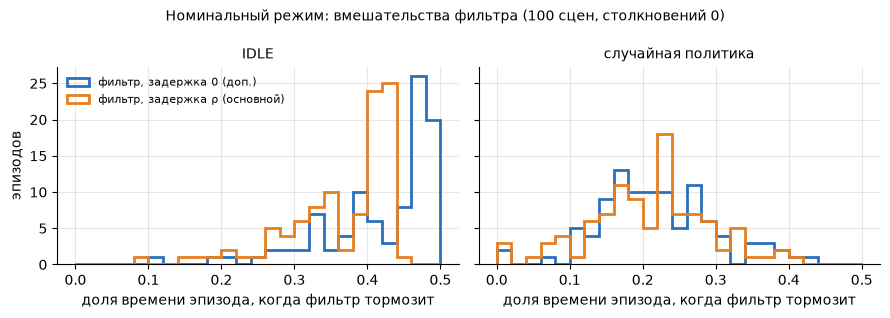

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
colors = {0.0: '#2c6fbb', 0.5: '#e67e22'}
bins = np.linspace(0, 0.5, 26)
for ax, policy, title in zip(axes, ['idle', 'random'], ['IDLE', 'случайная политика']):
    for d in (0.0, 0.5):
        x = outcomes[(outcomes.policy == policy) & outcomes.shield & (outcomes.reaction_delay == d)]
        ax.hist(x['доля времени фильтр тормозит'], bins=bins, histtype='step', linewidth=2,
                color=colors[d], label=NAMES[(True, d)])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('доля времени эпизода, когда фильтр тормозит')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('эпизодов')
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle('Номинальный режим: вмешательства фильтра (100 сцен, столкновений 0)', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '05_shield_share.png', dpi=150)

У IDLE фильтр тормозит больше, чем у случайной политики: случайная политика часто сама нажимает SLOWER или уходит в свободную полосу, а IDLE всегда давит на газ. С задержкой 0 фильтр включается и выключается чаще (≈ 63 раза за эпизод против ≈ 33 при задержке ρ): мгновенный фильтр реагирует на каждое касание границы d_min.

In [5]:
def switches(log):
    return int((log['shield_active'].astype(int).diff().abs() == 1).sum())

pd.DataFrame({
    NAMES[(True, d)]: [np.mean([switches(LOGS['idle'][(s, 1.0, True, d)]) for s in SEEDS])]
    for d in (0.0, 0.5)
}, index=['IDLE: включений/выключений фильтра за эпизод (среднее)']).round(1)

,"фильтр, задержка 0 (доп.)","фильтр, задержка ρ (основной)"
IDLE: включений/выключений фильтра за эпизод (среднее),63.4,32.7


## Фоновые машины нарушают поперечное допущение RSS

Фоновые машины перестраиваются по модели MOBIL, а не по поперечной RSS, и сдвигаются вбок быстро (до ~5 м/с). Иногда машина впереди агента начинает сдвигаться к нему, когда продольно она уже ближе d_min: в его полосу или в соседнюю. По RSS это опасная ситуация, и создает ее фоновая машина. Ищем такие моменты: впереди появилась новая опасная машина (продольно и поперечно ближе d_min), а сам агент последние 3 с полосу не менял (`unsafe_entries`). Первые 3 с эпизода не считаем: highway-env расставляет машины на старте случайно, без учета d_min (сколько эпизодов начинаются с зазора меньше d_min — ниже). У IDLE агент полосу не меняет никогда, поэтому для него подсчет точный.

In [6]:
ue = outcomes[outcomes.shield].groupby(['policy', 'вариант'], sort=False).agg(
    эпизодов_с_событием=('опасных событий от фона', lambda x: int((x > 0).sum())),
    событий_всего=('опасных событий от фона', 'sum'),
)
ue

эпизодов_с_событием  событий_всего
policy вариант                                                          
idle   фильтр, задержка ρ (основной)                    8             13
       фильтр, задержка 0 (доп.)                       10             13
random фильтр, задержка ρ (основной)                   46             92
       фильтр, задержка 0 (доп.)                       49             85

In [7]:
start_unsafe = np.mean([
    (LOGS['idle'][(s, 1.0, True, 0.5)]['gap'].iloc[0] < LOGS['idle'][(s, 1.0, True, 0.5)]['d_min'].iloc[0])
    for s in SEEDS])
print(f'Эпизодов, где на первом шаге зазор до машины впереди меньше d_min: {start_unsafe:.0%}')

Эпизодов, где на первом шаге зазор до машины впереди меньше d_min: 52%


,seed,t,зазор / d_min
0,0,3.33,0.99
1,11,6.33,0.66
2,29,3.47,0.93
3,40,36.20,0.16
4,44,5.00,0.10
5,63,3.07,0.41
6,63,3.33,0.84
7,64,31.27,-0.02
8,77,3.07,0.05
9,77,3.27,0.97


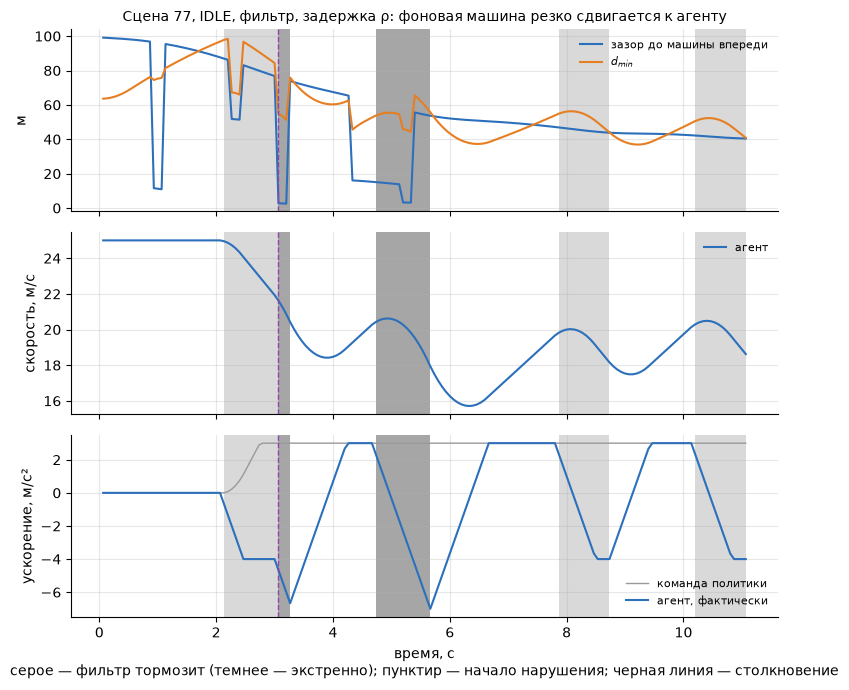

In [8]:
rows = []
for s in SEEDS:
    ev = unsafe_entries(LOGS['idle'][(s, 1.0, True, 0.5)])
    rows += [(s, r.t, r.ratio) for r in ev.itertuples()]
ev_idle = pd.DataFrame(rows, columns=['seed', 't', 'зазор / d_min'])
# пример: самое близкое событие с положительным зазором
seed_ex, t_ex = ev_idle[ev_idle['зазор / d_min'] > 0].sort_values('зазор / d_min').iloc[0][['seed', 't']]
seed_ex = int(seed_ex)
log = LOGS['idle'][(seed_ex, 1.0, True, 0.5)]
win = log[(log.t > t_ex - 4) & (log.t < t_ex + 8)]
axes = plot_episode(win, f'Сцена {seed_ex}, IDLE, фильтр, задержка ρ: '
                    f'фоновая машина резко сдвигается к агенту')
for ax in axes:
    ax.axvline(t_ex, color='#8e44ad', linewidth=1, linestyle='--')
axes[0].set_ylim(-2, None)
plt.gcf().tight_layout()
plt.gcf().savefig(FIG / '05_background_cutin.png', dpi=150)
ev_idle.round(2)

На графике (фиолетовый штрих — момент события) зазор скачком падает почти до нуля: фоновая машина резко сдвигается к агенту, когда продольно она уже ближе d_min. Фильтр тормозит. Столкновения не было.

По строгой RSS в такой ситуации (продольно машины уже были ближе d_min, когда возникла поперечная опасность) правильный ответ — поперечный, продольное торможение не обязательно. Наш фильтр тормозит всегда — это осторожнее, чем требует RSS.

«Номинальный режим» номинален по продольному допущению (торможение ≤ 5 м/с²), но фон иногда нарушает поперечное. Варианты: (а) оставить как есть и описать как свойство фона, одинаковое для всех β и γ; (б) запретить фону перестраиваться ближе d_min к агенту. Вопрос для письма преподавателю.

## Выводы этапа 5

1. Критерий готовности выполнен: в номинальном режиме с фильтром 0 столкновений из 100 для каждой из двух политик и каждой из двух задержек, с рывком 10 м/с³ и d_min с учетом рывка. Верхняя 95 % граница частоты — около 3 % на вариант. Без фильтра — 93–96 из 100.
2. По дороге найдена и исправлена ошибка реализации: фильтр мог «отменить» уже фактически законченное перестроение и увести агента в занятую исходную полосу (один боковой удар у случайной политики). Теперь перестроение завершено, как только агент пересек разметку, а отмена — только если возвращаться безопасно.
3. Фильтр не «покупает» безопасность остановкой: агент едет ≈ 21–22 м/с, все эпизоды доходят до конца времени. Экстренных торможений около 1–2 % времени.
4. Фоновые машины иногда резко сдвигаются к агенту, когда продольно уже ближе d_min (MOBIL не знает RSS). Это одинаково для всех уровней β и γ.
5. Наш фильтр на любую опасность впереди отвечает продольным торможением; строгая RSS в части случаев требует только поперечного ответа.
6. highway-env расставляет машины на старте без учета d_min: с новой (большей) d_min таких эпизодов 52 %. Нарушения начинаются не раньше 3 с.